## Exploring Color Spaces

This notebook follows the lecture transcript and explores why color space conversion matters in OpenCV. We will review **RGB, grayscale, HSV, LAB, and BGR**, and then use `cv2.cvtColor()` to convert between them in practice.

### Why We Convert Color Spaces

- Different devices may expect different channel orders. For example, one system may provide images in **RGB** while another expects **BGR**.
- A color space defines how pixel values represent color, brightness, or intensity.
- Choosing the right color space makes processing easier for tasks such as visualization, segmentation, tracking, and efficient analysis.

In [3]:
import cv2 as cv
import matplotlib.pyplot as plt

### RGB and OpenCV's BGR Format

- **RGB** stands for red, green, and blue. It is an **additive color model**, so combining high values from all three channels produces white.
- Each channel ranges from `0` to `255`. Examples: pure red `(255, 0, 0)`, pure green `(0, 255, 0)`, pure blue `(0, 0, 255)`, and white `(255, 255, 255)`.
- RGB closely matches how humans and digital displays represent color.
- In OpenCV, `cv2.imread()` loads images in **BGR** order for historical compatibility, which means the first channel is blue, the second is green, and the third is red.

In [4]:
img_path = "../../data/raw/images/mountain.png"

Image loaded successfully

Shape of the image:  (720, 1080, 3)


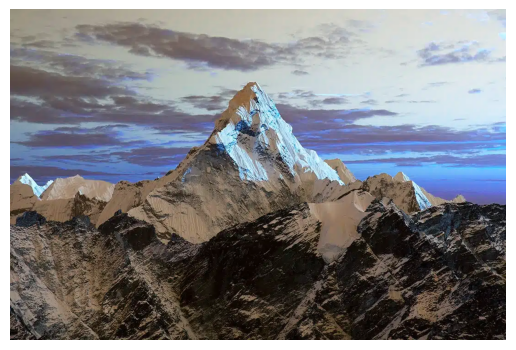

In [6]:
## Load image as bgr
bgr_image = cv.imread(img_path)

if bgr_image is None:
    print("Error: Cound not load the image.")
else:
    print("Image loaded successfully\n")
    print("Shape of the image: ", bgr_image.shape)
    plt.imshow(bgr_image)
    plt.axis('off')
    plt.show()

### Grayscale

- Grayscale uses **one channel** instead of three.
- Pixel intensity ranges from `0` to `255`: `0` means black, `255` means white, and values in between represent shades of gray.
- It is useful when color information is not important because it reduces memory usage and computation.
- This is helpful when we only care about structure or objects, such as detecting cars without caring whether they are red, white, or black.

In [8]:
## Convert to gray scale
gray_image=cv.cvtColor(bgr_image, cv.COLOR_BGR2GRAY)
cv.imwrite("../../data/processed/mountain_gray.jpg", gray_image)

True

### HSV

- **H** stands for hue and represents the color type. It is often described on a wheel from `0` to `360` degrees.
- **S** stands for saturation and represents the purity of the color, usually from `0%` to `100%`.
- **V** stands for value and represents brightness, also usually from `0%` to `100%`.
- HSV is especially useful for color-based tasks such as thresholding, segmentation, and object tracking because it separates color from intensity.

In [9]:
## Convert to hsv
hsv_image = cv.cvtColor(bgr_image, cv.COLOR_BGR2HSV)
cv.imwrite("../../data/processed/mountain_hsv.jpg", hsv_image)

True

#### Why the HSV Output Looks Strange

HSV images usually look unusual to us because HSV is mainly meant for **calculation**, not for human-friendly visualization. In practice, HSV is useful when we want to isolate a color range, such as selecting a green-screen background and replacing it with something else.

And in our code:

```python
# BUG: we used a standard viewer meant that is only usable for normal BGR/RGB images. That's why it tries to write the hsv as RGB image.
cv2.imwrite('output.png', hsv_image) 
```
A standard image viewer or web browser doesn't know what "HSV" is; it treats every 3-channel image as standard RGB/BGR. It forces the Hue numbers to render as Red, Saturation numbers as Green, and Value numbers as Blue.

### LAB

- **L** represents lightness or brightness, moving from black to white.
- **A** represents the **green-to-red** component.
- **B** represents the **blue-to-yellow** component.
- LAB is designed to be closer to human color perception and is often useful for color correction and adjustment.
- Compared with HSV, LAB can be less intuitive when we want to target a very specific color range.

In [10]:
## Convert to LAB format
lab_image = cv.cvtColor(bgr_image, cv.COLOR_BGR2LAB)
cv.imwrite("../../data/processed/mountain_lab.jpg", lab_image)

True

### BGR in OpenCV

- **BGR** is essentially the same as RGB, except the blue and red channels are swapped.
- OpenCV uses BGR as its default color format mainly for historical compatibility.
- Unlike HSV or LAB conversion, converting between `BGR` and `RGB` is mainly a **channel swap**.
- This becomes important whenever we move images between OpenCV and tools that expect RGB.

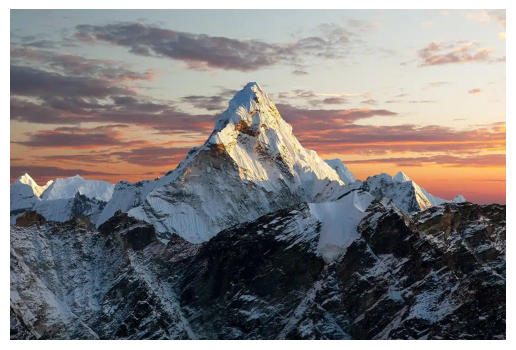

In [12]:
## Convert to RGB
rgb_image = cv.cvtColor(bgr_image, cv.COLOR_BGR2RGB)
cv.imwrite("../../data/processed/mountain_rgb.jpg", rgb_image)
plt.imshow(rgb_image)
plt.axis('off')
plt.show()

In [ ]:
## Convert to RGB
bgr_image=cv.cvtColor(rgb_image, cv.COLOR_RGB2BGR)
cv.imwrite("../data/processed/mountain_bgr.jpg", bgr_image)

True

### Why RGB Output Can Look Wrong in OpenCV

- `cv2.cvtColor(..., cv2.COLOR_BGR2RGB)` swaps channel `0` and channel `2`.
- After that step, the array is now in **RGB** order, but OpenCV functions such as `cv2.imwrite()` still assume they are receiving a **BGR** image.
- Because of that expectation, saving an RGB array directly with OpenCV can produce a strange blue/red-shifted result.
- This is why the original image can look correct when saved directly, while the explicitly converted RGB version can look wrong.

### Key Takeaways

- **RGB** is the common display-oriented color model, while OpenCV internally defaults to **BGR**.
- Use **grayscale** when color is unnecessary and efficiency matters.
- Use **HSV** when you want to isolate, threshold, or segment colors.
- Use **LAB** when working with perception-oriented color adjustments.
- Most color conversions in OpenCV are straightforward with `cv2.cvtColor()`, and RGB/BGR confusion is usually a channel-order issue.